# 1. Replicating Moreira & Muir (2017), Table 1

Volatility-managed factor:

$$f^{\sigma}_t = \frac{c}{RV^2_{t-1}} \, f_t$$

where $RV^2_{t-1}$ is last month's realized variance and $c$ makes $f^\sigma$ and $f$ have the same full-sample volatility.
We then run the spanning regression $f^{\sigma}_t = \alpha + \beta f_t + \varepsilon_t$ (HC1 standard errors, annualized).

Data: Kenneth French Data Library, sample 1926-07 to 2015-12 to match the paper.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from data_loaders import load_us_factors
from vol_tools import realized_variance, vol_managed, spanning_regression, sharpe

pd.set_option("display.float_format", "{:.2f}".format)

## Data

In [2]:
monthly, daily = load_us_factors()
monthly = monthly.loc[:"2015-12"]
daily = daily.loc[:"2015-12-31"]
print("monthly:", monthly.index[0], "->", monthly.index[-1])
print("daily:  ", daily.index[0].date(), "->", daily.index[-1].date())

monthly: 1926-07 -> 2015-12
daily:   1926-07-01 -> 2015-12-31


## Build volatility-managed factors

In [3]:
factors = {"Mkt": "Mkt-RF", "Mom": "Mom"}

f, rv, fs, w = {}, {}, {}, {}
for name, col in factors.items():
    f[name] = monthly[col].dropna()
    rv[name] = realized_variance(daily[col].dropna())
    fs[name], w[name], _ = vol_managed(f[name], rv[name])

# sanity check: the Oct 1987 crash should cut the position in Nov 1987, not Oct 1987
print(f"Mkt position: 1987-10 = {w['Mkt']['1987-10']:.2f}, 1987-11 = {w['Mkt']['1987-11']:.2f}")

Mkt position: 1987-10 = 0.52, 1987-11 = 0.02


## Spanning regression vs. the paper

In [4]:
paper = pd.DataFrame({
    "Mkt": {"alpha": 4.86, "alpha_se": 1.56, "beta": 0.61, "N": 1065, "r2": 0.37, "rmse": 51.39},
    "Mom": {"alpha": 12.51, "alpha_se": 1.71, "beta": 0.47, "N": 1060, "r2": 0.22, "rmse": 50.37},
})
mine = pd.DataFrame({name: spanning_regression(fs[name], f[name]) for name in factors})

cols = ["alpha", "alpha_se", "beta", "N", "r2", "rmse"]
print(pd.concat({"paper": paper.loc[cols], "replication": mine.loc[cols]}, axis=1))
print()
for name in factors:
    t = mine.loc["alpha", name] / mine.loc["alpha_se", name]
    print(f"{name}: alpha t-stat = {t:.2f}, appraisal ratio = {mine.loc['appraisal', name]:.2f}")

           paper         replication        
             Mkt     Mom         Mkt     Mom
alpha       4.86   12.51        4.88   12.80
alpha_se    1.56    1.71        1.56    1.72
beta        0.61    0.47        0.60    0.45
N        1065.00 1060.00     1073.00 1068.00
r2          0.37    0.22        0.36    0.20
rmse       51.39   50.37       51.66   50.99

Mkt: alpha t-stat = 3.13, appraisal ratio = 0.33
Mom: alpha t-stat = 7.46, appraisal ratio = 0.87


Small differences come from revisions to the French data since the paper was written.

## Sharpe ratios

In [5]:
for name in factors:
    s0, s1 = sharpe(f[name].loc[fs[name].index]), sharpe(fs[name])
    print(f"{name}: original {s0:.2f} -> managed {s1:.2f} ({s1 / s0 - 1:+.0%})")

Mkt: original 0.42 -> managed 0.51 (+23%)
Mom: original 0.49 -> managed 1.00 (+103%)


## Positions and cumulative returns

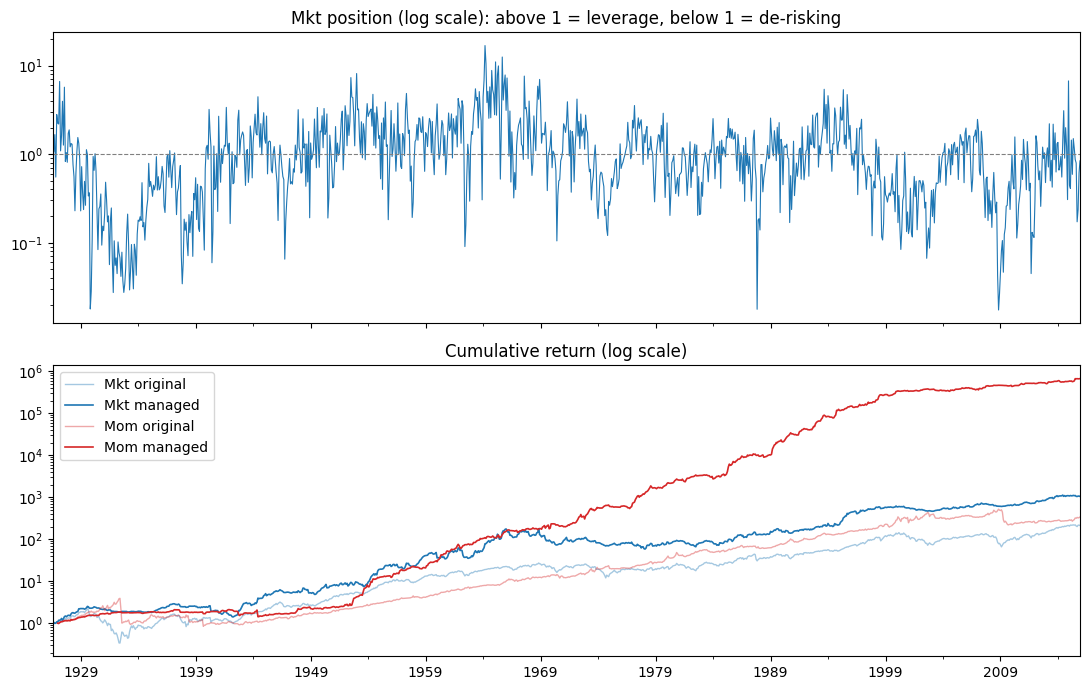

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

w["Mkt"].to_timestamp().plot(ax=axes[0], lw=0.8)
axes[0].axhline(1, color="gray", ls="--", lw=0.8)
axes[0].set_yscale("log")
axes[0].set_title("Mkt position (log scale): above 1 = leverage, below 1 = de-risking")

for name, col in [("Mkt", "C0"), ("Mom", "C3")]:
    (1 + f[name].loc[fs[name].index]).cumprod().to_timestamp().plot(
        ax=axes[1], color=col, alpha=0.4, lw=1, label=f"{name} original")
    (1 + fs[name]).cumprod().to_timestamp().plot(
        ax=axes[1], color=col, lw=1.2, label=f"{name} managed")
axes[1].set_yscale("log")
axes[1].set_title("Cumulative return (log scale)")
axes[1].legend()
plt.tight_layout()
plt.show()